In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

# Question 1

In [2]:
# Fixed 2024-25 season data, not a live feed.
url = ("https://raw.githubusercontent.com/Data-Dunkers/data/main/"
       "NBA/player/nba_player_stats_2024-2025.csv")
nba_full = pd.read_csv(url)

stats = ["PTS", "REB", "AST", "3PA", "STL", "BLK"]
nba = nba_full.loc[
    (nba_full["GP"] >= 40) & (nba_full["MIN"] >= 20),
    ["Name", "POS", "GP", "MIN"] + stats
].dropna().drop_duplicates(subset="Name").reset_index(drop=True)

# Adjust for playing time: per-36-minute statistics
for stat in stats:
    nba[stat + "_36"] = nba[stat] / nba["MIN"] * 36
features = [stat + "_36" for stat in stats]

print("Number of players:", len(nba))
display(nba[["Name", "POS", "GP", "MIN"] + features].head())

Number of players: 229


,Name,POS,GP,MIN,PTS_36,REB_36,AST_36,3PA_36,STL_36,BLK_36
0,Aaron Gordon,F,51,28.4,18.633803,6.084507,4.056338,4.309859,0.633803,0.380282
1,Aaron Nesmith,G,45,24.9,17.349398,5.783133,1.734940,6.216867,1.156627,0.578313
2,Aaron Wiggins,G,76,22.9,18.864629,6.131004,2.829694,7.074236,1.257642,0.314410
3,AJ Green,G,73,22.7,11.735683,3.806167,2.378855,7.929515,0.792952,0.158590
4,Al Horford,C,60,27.7,11.696751,8.057762,2.729242,6.758123,0.779783,1.169675


In [3]:
X_raw = nba[features].copy()
summary = X_raw.agg(["mean", "std", "min", "max"]).T.round(2)
display(summary)

scaler = StandardScaler()
X_z = scaler.fit_transform(X_raw)
plot_z = pd.DataFrame(X_z, columns=[f + "_z" for f in features])
plot_z["Name"] = nba["Name"]

fig = px.scatter(nba, x="AST_36", y="REB_36", hover_name="Name",
                 title="Raw per-36 profiles (2 of 6 features)")
fig.show()

fig = px.scatter(plot_z, x="AST_36_z", y="REB_36_z", hover_name="Name",
                 title="Standardized profiles: the same players")
fig.show()

,mean,std,min,max
PTS_36,17.53,5.00,7.81,34.42
REB_36,6.49,2.88,2.21,14.64
AST_36,4.01,2.05,1.19,11.60
3PA_36,5.79,2.67,0.00,12.60
STL_36,1.20,0.39,0.33,3.20
BLK_36,0.70,0.58,0.10,4.12


## Part A

Each row represents an NBA player who appeared in at least 40 games and averaged at least 20 minutes in the 2024-2025 NBA season. This is unsupervised rather than a KNN classification problem because none of the players have archetype labels; we are not predicting archetype labels, but instead we are attempting to create archetype labels based on how similar players are according to their per-36 statistics. 

In general, including POS is a judgement call. Namely, do we want our player archetypes to be influenced by their position? In this assignment, the instructions explicitly say that we should not include POS, and one line of justification is that including it may lead to clusters that largely group by position, which is not novel or insightful. Still, POS may be useful after clustering, as it may help thematically identify groups. 


(If we want archetypes to factor in player position, then we can use player position, though it will require additional care because it is a categorical variable; naively encoding positions 1 to 5 imposes an implicit weighting/emphasis on the position, and it makes an assumption that certain positions are more different from each other than others. Other alternatives, such as Gower distance, may be more suitable for accomodating position.)

## Part B

PTS-36 has the largest standard deviation, about 1.75x the next greatest. Relative to last week's lab, this discrepancy is not as egregious, but it is still significant. Raw Euclidean distances can be thought of as the sum of squared differences, squared rooted; each squared difference takes the difference of two observations from the same distribution of one predictor. For simplicitly, we may consider these observations as independent (and identically distributed). In that case, we are interested in identifying $E((X_i - X_j)^2)$ for each component. That is, $E((X_i - X_j)^2) = E(X_i^2 - 2X_iX_j + X_j^2) = E(X_i^2) - 2E(X_iX_j) + E(X_j^2) = E(X_i^2) - 2E(X_i)E(X_j) + E(X_j^2) = \sigma^2 + \mu^2 - 2 \mu^2 + \sigma^2 + \mu^2 = 2\sigma^2$. Thus, the squared quantity is expected to be largest for the variable with the largest standard deviation, and the Euclidean distance calculation will be dominated by this component. The key point is that standard deviation and variance is influenced by the unit representation and not underlying importance. We could, for instance, divide all PTS_36 values by $16$, and now it would have the smallest standard deviation in the data. In this alternative representation, the original information is entirely preserved, so, if spread was somehow a proxy for importance, then the same information (in two different representations) would simultaneously be the most and least informative; this is nonsensical.

## Part C

The purpose of the per 36 minute adjustment is to account for the fact that players may play a different total number of minutes per game. If a did not consider a rate basis, then players would largely group based on their playing volume (players who play more minutes will tend to aggregate more of all statistics). In certain settings, this may be a useful insight, but, here, we are more interested in representing play styles, and styles are best understood through rates (high scorers are players who score a lot when they are on the court and not neccesarily those who scored the most, which include those who accumulated these points just by playing a lot of minutes on average). Standardization addresses the fact that using a 36 minute normalization is a representation where the spread of each predictor is different because each comes from a different distribution with different natural spreads; components with the most variance will dominate the resulting distance metric (see the discussion in part B). When we standardize, we enforce all predictors to have a mean of $0$ and (more importantly) a variance of $1$, meaning their expected contributions to the distance metric are equal. The conceptual heuristic is that this places all predictors on an even playing field to contribute, though one could argue that we are possibly losing useful information about the spread of the variable in the native units.

# Question 2

In [4]:
# Fix K=4 for a common comparison later. There is no true K supplied.
kmeans4 = KMeans(n_clusters=4, random_state=123, n_init=20)
nba["KMeans"] = kmeans4.fit_predict(X_z)

print("K-means cluster sizes:")
display(nba["KMeans"].value_counts().sort_index().rename("Players"))

print("Cluster averages, in original per-36 units:")
display(nba.groupby("KMeans")[features].mean().round(1))

z_profiles = pd.DataFrame(X_z, columns=features)
z_profiles["KMeans"] = nba["KMeans"]
print("Cluster averages, in z-score units:")
display(z_profiles.groupby("KMeans")[features].mean().round(2))

# The most representative observed player is nearest to the cluster centroid.
representatives = []
for k in range(4):
    members = np.where(nba["KMeans"].to_numpy() == k)[0]
    distances = np.linalg.norm(X_z[members] - kmeans4.cluster_centers_[k], axis=1)
    i = members[np.argmin(distances)]
    representatives.append({"Cluster": k, "Representative player": nba.loc[i, "Name"]})
display(pd.DataFrame(representatives))

K-means cluster sizes:


KMeans
0    41
1    99
2    33
3    56
Name: Players, dtype: int64

Cluster averages, in original per-36 units:


,PTS_36,REB_36,AST_36,3PA_36,STL_36,BLK_36
KMeans,,,,,,
0,18.1,11.2,3.1,2.6,1.0,1.6
1,15.2,5.3,2.8,6.5,1.1,0.5
2,14.0,6.3,5.3,4.4,1.8,0.7
3,23.2,5.3,6.1,7.7,1.2,0.4


Cluster averages, in z-score units:


,PTS_36,REB_36,AST_36,3PA_36,STL_36,BLK_36
KMeans,,,,,,
0,0.12,1.65,-0.45,-1.21,-0.41,1.57
1,-0.46,-0.42,-0.59,0.27,-0.34,-0.37
2,-0.70,-0.08,0.63,-0.53,1.51,-0.07
3,1.14,-0.43,1.01,0.71,0.01,-0.46


,Cluster,Representative player
0,0,Onyeka Okongwu
1,1,Nikola Jovic
2,2,Jake LaRavia
3,3,Austin Reaves


,K,WCSS,Silhouette
0,2,1017.663,0.337
1,3,815.272,0.242
2,4,687.392,0.249
3,5,637.056,0.174
4,6,591.509,0.200
5,7,543.392,0.178
6,8,504.898,0.189


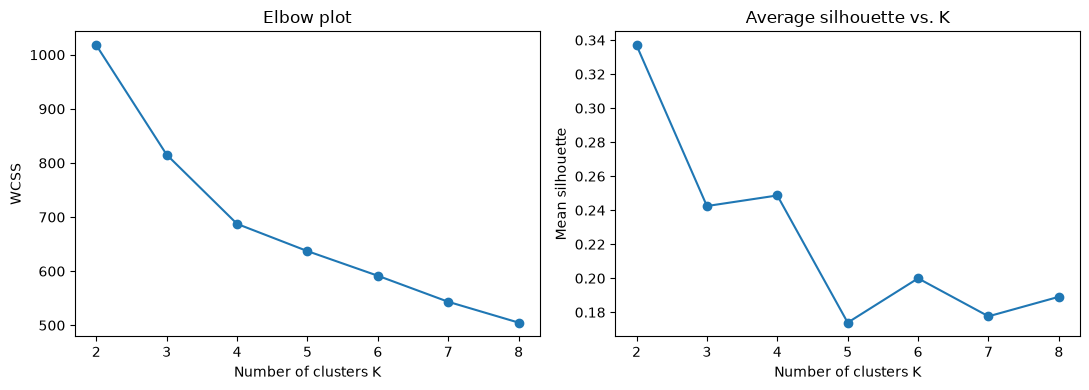

In [5]:
# Both plots use the SAME standardized six-dimensional features.
results = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=20, random_state=123).fit(X_z)
    results.append({"K": k, "WCSS": model.inertia_,
                    "Silhouette": silhouette_score(X_z, model.labels_)})
k_scores = pd.DataFrame(results)
display(k_scores.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(k_scores["K"], k_scores["WCSS"], marker="o")
ax[0].set(xlabel="Number of clusters K", ylabel="WCSS", title="Elbow plot")
ax[1].plot(k_scores["K"], k_scores["Silhouette"], marker="o")
ax[1].set(xlabel="Number of clusters K", ylabel="Mean silhouette",
          title="Average silhouette vs. K")
plt.tight_layout()
plt.show()

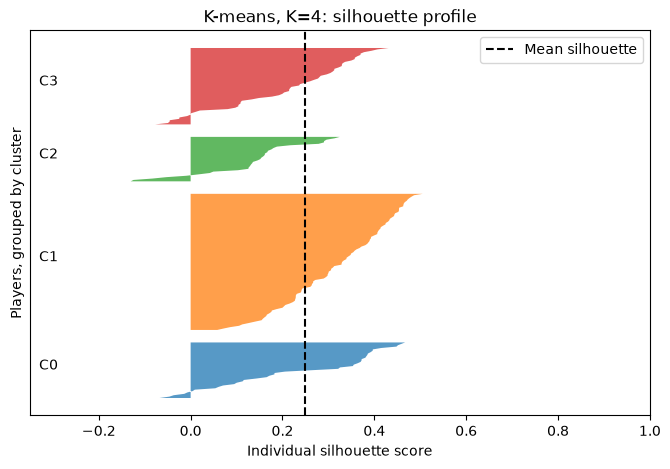

In [6]:
# Silhouette profile: each horizontal strip represents one player.
values = silhouette_samples(X_z, nba["KMeans"])
fig, ax = plt.subplots(figsize=(8, 5))
left_bound = min(-0.35, float(values.min()) - 0.05)
y0 = 8
for k in sorted(nba["KMeans"].unique()):
    cluster_values = np.sort(values[nba["KMeans"].to_numpy() == k])
    y1 = y0 + len(cluster_values)
    ax.fill_betweenx(np.arange(y0, y1), 0, cluster_values, alpha=0.75)
    ax.text(left_bound + 0.02, (y0 + y1) / 2, f"C{k}")
    y0 = y1 + 8
ax.axvline(values.mean(), color="black", linestyle="--", label="Mean silhouette")
ax.set(xlim=(left_bound, 1), xlabel="Individual silhouette score",
       ylabel="Players, grouped by cluster", title="K-means, K=4: silhouette profile")
ax.set_yticks([])
ax.legend()
plt.show()

# Two-dimensional display; the six-dimensional features determine clusters.
fig = px.scatter(nba, x="AST_36", y="REB_36", hover_name="Name",
                 color=nba["KMeans"].astype(str),
                 labels={"color": "K-means cluster"},
                 title="K-means assignments (2D view of a 6D clustering)")
fig.show()

## Part A

For a group of points in a current cluster, the centroid is the average of all of the points; more precisely, we average each entry component-wisely, and this produces a point in the coordinate space. A centroid is not neccesarily a player because it is the average of all of the players in the cluster, which is not guaranteed to match a particular player; the average family has $2.3$ children but this is clearly never possible. 

In the assignment process for $K=4$, our setting is the six dimensional standardized coordinate space, where each dimension corresponds to one of the standardized rate metrics. We begin by assuming we have four centroids (which either come from the previous step or are intialized using a selected procedure in the first step). Then, (1) we compute each point's distance to the four centroids. For each point, we re-assign it to the cluster corresponding to the centroid who it resides closest to according to Euclidean distance. At this point, each point has been assigned to a possibly new cluster from the previous step. (2) For each such cluster, we compute a new centroid, which is the average of the points that were assigned to this cluster; this can possibly yield a different centroid from the previous step. It can be shown that repeated application of this two step process never increases the objective WCSS (with fixed-K), and the process stops if no points are re-assigned to different clusters OR we reach some pre-specified iterative threshold.




## Part B

Visually, the elbow plot for WCSS gives an elbow of $K = 4$. Mathematically, WCSS drops by about $200$ from $K=2$ to $K=3$, and then it drops by about $128$ from $K=3$ to $K=4$. Additional increases in $K$ only result in marginal decreases of between $40$ and $50$, which visually appears as the forearm of the elbow. The silhoutee plot, on the other hand, presents possibly two different candidate values, the largest silhouette score occurs when $K=2$, which yields a value of $0.337$. The second highest silhouette score is $0.249$, which occurs at $K=4$. Thus, $K = 2$ is by the far best cluster size based on silhouette score, but this is where domain knowledge becomes important. We would generally expect more than $2$ archetypes, and it is likely that the $K = 2$ split is picking up on coarser patterns (big men (positions 3-5) v. perimeter players (positions 1-2)), which I would argue is too broad to be archetypes and arguably even more broad than position. Thus, I would choose $K=4$. 

Selecting based on WCSS is misleading because it can be shown that WCSS is generally decreasing with respect to $K$; conceptually, more clusters means fewer points in each cluster on average, meaning that each point has a larger "pull" on the centroid it is assigned to. Indeed, adding another centroid can never hurt the WCSS contribution of any point, and thus, the entire WCSS calculation. In an extreme case where the number of clusters is equal to the number of points, the WCSS is zero. Since WCSS does not consider how points from different clusters relate to one another, there is also no penalty for making many clusters that are very close to one another, which often happens as we increase $K$. Silhouette score, alternatively, will penalize cluster arrangements that produce many close clusters, so its metric is generally not monotonic with respect to $K$. 

From the silhouette profile, we see that the majority of silhouette scores sit above $0$. Relatively speaking, this clustering arrangement seems to label cluster $1$ the most definitively in the sense that it has the highest proportion of silhouette scores above the average (close to $75\%$) and none are negative (which would mean that the point is closer, on average, to points outside of its cluster than within); this means that cluster $1$ points are generally close to other points in their cluster and far from points not in its cluster. Cluster $3$ and $0$ are more modest, with around $40\%$ of points sitting above the unconditional average and approximately $10\%$ of the points having negative silhouette scores. Finally, Cluster $2$ is the least definitive, with only about $10\%$ of its points above the unconditional average and approximately $10\%$ of the points having negative silhouette scores. So, poorly placed players are disproportionately coming from cluster $2$, though there are non-trivial relative contributions coming from cluster $3$ and cluster $0$.

## Part C

Two of the clusters stand out. For each measurement, I provide the standardized and unstandardized in succession. 

Cluster 0 has average rebound rates (11.2) that are 1.65 standard deviations above the unconditional average and block rates (1.6) that are 1.57 standard deviations above the unconditional average; meanwhile, their point-scoring is about the uncondiitonal average (0.12, 18.1) and their assists (-0.45, 3.1), steal (-0.41, 1.0), and especially 3 point attempt rates (-1.21, 2.6) are firmly below the unconditional average. These averages suggest an interior bruiser whose main role is to defend the rim; this leads to high rebound and block rates. The representative player, center Onyeka Okongwu, agrees with this archetype. 

The second is cluster 3, which have average point (1.14, 23.2) and assist rates (1.01, 6.1) firmly above the unconditional average. Additionally, three point rates are moderately high (0.71, 7.7) while steals are about the unconditional average (0.01, 1.2). Rebounds and blocks, on the other hand, are firmly below average (-0.43/5.3  and -0.46/0.4,  respectively). These averages suggest an on-ball playmaker who scores a lot but also facilitates scoring; unlike the interior bruiser, the on-ball playmaker is generally on the perimeter and away from the paint. The representative player, two-guard Austin Reeves, agrees with this archetype. 

These should not be treated as definitive player positions since a given cluster may contain multiple positions. Moreover, the groups depend on the choices of clusters, which, although a decision made with evidence, is not inherently right. Finally, the average silhouette score of 0.249 is moderate, and we identified that each group (except cluster 1) has a non-trivial proportion of negative silhouette scores; these players are closer, on average, to players outside of their cluster than those inside it.

# Question 3

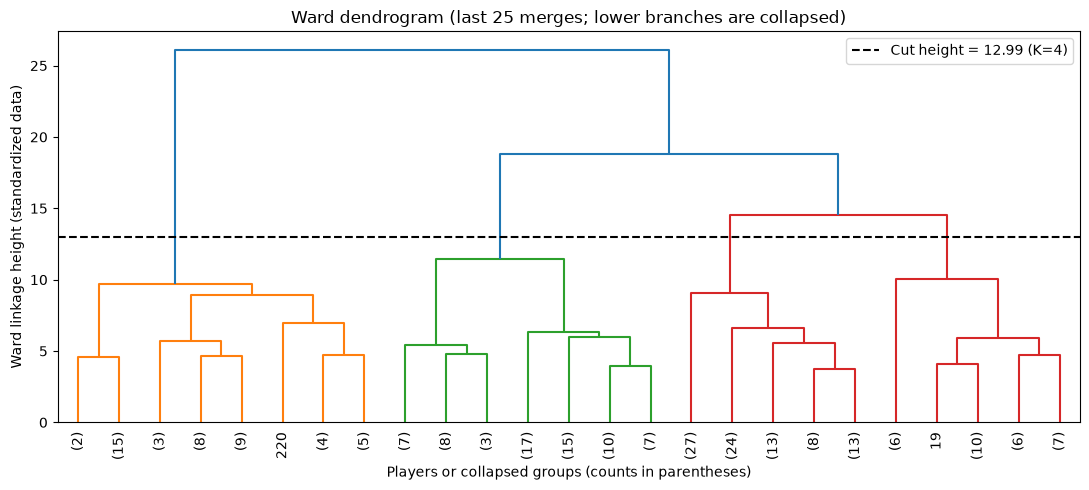

In [7]:
# Bottom-up hierarchical clustering: start with one cluster per player.
ward_tree = linkage(X_z, method="ward", metric="euclidean")

# The cut is halfway between the merge that leaves 4 groups and the next merge.
cut_height = (ward_tree[-4, 2] + ward_tree[-3, 2]) / 2

plt.figure(figsize=(11, 5))
dendrogram(ward_tree, truncate_mode="lastp", p=25,
           show_leaf_counts=True, leaf_rotation=90)
plt.axhline(cut_height, color="black", linestyle="--",
            label=f"Cut height = {cut_height:.2f} (K=4)")
plt.title("Ward dendrogram (last 25 merges; lower branches are collapsed)")
plt.xlabel("Players or collapsed groups (counts in parentheses)")
plt.ylabel("Ward linkage height (standardized data)")
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
nba["Ward"] = fcluster(ward_tree, t=4, criterion="maxclust")

print("Cut height:", round(cut_height, 3))
print("Ward groups at K=4:")
display(nba["Ward"].value_counts().sort_index().rename("Players"))

print("Ward group averages, per 36 minutes:")
display(nba.groupby("Ward")[features].mean().round(1))

Cut height: 12.993
Ward groups at K=4:


Ward
1    47
2    67
3    85
4    30
Name: Players, dtype: int64

Ward group averages, per 36 minutes:


,PTS_36,REB_36,AST_36,3PA_36,STL_36,BLK_36
Ward,,,,,,
1,17.8,10.9,3.1,3.0,1.0,1.5
2,22.8,5.4,5.2,7.7,1.1,0.5
3,14.2,5.3,2.9,6.1,1.2,0.5
4,14.9,5.3,6.0,5.0,1.8,0.6


In [9]:
# Complete linkage merges using the farthest pair across two groups.
complete_tree = linkage(X_z, method="complete", metric="euclidean")

h_scores = []
for method, tree in [("Ward", ward_tree), ("Complete", complete_tree)]:
    for k in range(2, 9):
        groups = fcluster(tree, t=k, criterion="maxclust")
        h_scores.append({"Linkage": method, "K": k,
                         "Silhouette": silhouette_score(X_z, groups)})
h_scores = pd.DataFrame(h_scores)
display(h_scores.pivot(index="K", columns="Linkage", values="Silhouette").round(3))

fig = px.line(h_scores, x="K", y="Silhouette", color="Linkage", markers=True,
              title="Hierarchical clustering: silhouette vs. cut K")
fig.show()

Linkage,Complete,Ward
K,,
2,0.345,0.305
3,0.334,0.204
4,0.163,0.201
5,0.199,0.178
6,0.183,0.189
7,0.169,0.180
8,0.181,0.144


## Part A

Agglomerative clustering refers to a bottom-up clustering procedure, where all observations are originally separate clusters, and we repeatedly merge the two "closest" clusters based on a particular metric until only one cluster remains. Recall that Ward linkage chooses the next pair of clusters to merge based on whichever pair results in the smallest increase in WCSS. Technically scipy displays a transformed height of $\sqrt{2\Delta WCSS}$, but this may be conceptually restranslated into values of $\Delta WCSS$. A low height means that the merging of two clusters results in a relatively small change in WCSS, meaning they are relatively similar groups. On the flip side, a high height means the marging of two clusters results in a relatively large change in WCSS, meaning they are relatively different groups.

Whenever at least one cluster in the pair contains more than one point, the change in WCSS is dependent on the current centroids and their cluster sizes ($\Delta(A, B) = \frac{n_An_B}{n_A + n_B}||\bar{a}-\bar{b}||^2$), not on the Euclidean distance between any two points in the cluster. The exception is if the clusters are each a point. In that case, we see from the formula that $\Delta(X, Y) = \frac{1}{2}||x-y||^2$ and $\sqrt{2\Delta WCSS} = ||x-y||$.

## Part B

The printed cut height is $12.993$, which produces $4$ Ward groups. We can think of horizontal cuts representing a time freeze, where all merges below it have occurred but none of the merges above it have. The persistence of a cluster is represented by a vertical line. Each vertical segment is a cluster that exists over the heights it spans, so a horizontal cut crosses exactly the clusters present at that height. A cluster persists until a merge occurs at some height, where a horizontal line signifies its union with another cluster; at this point, we may think of this union as a "new" cluster. So, if four vertical lines intersect with a horizontal line at a given height, then this implies four clusters persist at that height. 

At each height, we either merge one or more pairs of the clusters from the previous height or do not merge clusters from the previous height. For pairs of clusters that are merged, two clusters become one, meaning each merge reduces total clusters by one. If we do not merge at a certain height, then the number of clusters remain the same. Thus, the number of clusters is non-increasing with respect to height. In other words, the number of clusters can only stay the same or decrease with increasing height. 

## Part C

In [10]:
g2 = fcluster(ward_tree, t=2, criterion="maxclust")
display(pd.crosstab(nba["POS"], g2))

col_0,1,2
POS,,
C,28,2
F,16,66
G,2,108
PF,1,0
PG,0,2
SF,0,1
SG,0,3


For Ward linkage, the best silhouette score occurs at $K=2$ with value $0.305$. Alternatively, the best silhouette score for complete linkage occurs at $K =2$ with value $0.345$. In this case, the best silhouette scores agree. Even at the same $K$, the choice of linkage can change which players end up together. That is, two clusters can appear more or less similar depending on the linkage employed. In complete linkage, the merging process relies only on the two points (one from each cluster) that produce the largest pairwise distance. In this way, complete linkage is highly sensitive to outliers and is in some sense blind to the remaining points in each cluster. Ward linkage, on the other hand, implicitly relies on all points in its linkage computation. In a contrived but illustrative example, a spread out cluster compared to another spread out cluster with same mean would be merged at a height of $0$, but, due to the large spread of the points, its possible that two points in the clusters are very far from one another, so complete linkage will not merge this pair until a much higher height. Since agglomerative schemes are greedy, these merges are never reverted, meaning that tiny differences can aggregate over many merge decisions to lead to very different outcomes. Fundamentally, silhouette scores favor coarse splits, and they have no domain knowledge regarding basketball. Just as before, at $K=2$, these clustering schemes are picking up on the obvious split between interior bruisers (usually 4s and 5s) and perimeter players (1s, 2s, and 3s), and while this may optimize silhouette scores, it generates a grouping that is not useful for archetype analysis. Since silhouette score alone cannot factor in context, we as data scientists must validate $K$ based on our understanding of the underlying concept being modeled.

# Question 4

In [11]:
# Labels (0,1,2,3 vs. 1,2,3,4) are arbitrary; compare overlap, not numbers.
print("K-means vs. Ward membership overlap (both K=4):")
display(pd.crosstab(nba["KMeans"], nba["Ward"],
                    rownames=["K-means"], colnames=["Ward"]))

print("Agreement adjusted for chance (ARI):",
      round(adjusted_rand_score(nba["KMeans"], nba["Ward"]), 3))

K-means vs. Ward membership overlap (both K=4):


Ward,1,2,3,4
K-means,,,,
0,41,0,0,0
1,5,19,72,3
2,0,0,11,22
3,1,48,2,5


Agreement adjusted for chance (ARI): 0.527


In [12]:
# A deliberately unstandardized comparison (still per 36 minutes).
raw_kmeans4 = KMeans(n_clusters=4, n_init=20, random_state=123)
nba["RawKMeans"] = raw_kmeans4.fit_predict(X_raw)

print("K-means z-score vs. raw per-36 cluster agreement (ARI):",
      round(adjusted_rand_score(nba["KMeans"], nba["RawKMeans"]), 3))

print("Raw-data cluster means, per 36 minutes:")
display(nba.groupby("RawKMeans")[features].mean().round(1))

print("Cluster overlap (do NOT compare numeric label values as if matched):")
display(pd.crosstab(nba["KMeans"], nba["RawKMeans"]))

K-means z-score vs. raw per-36 cluster agreement (ARI): 0.318
Raw-data cluster means, per 36 minutes:


,PTS_36,REB_36,AST_36,3PA_36,STL_36,BLK_36
RawKMeans,,,,,,
0,16.4,11.4,3.3,2.0,1.2,1.3
1,18.0,5.2,3.9,7.3,1.2,0.5
2,25.2,6.4,5.6,7.2,1.2,0.7
3,12.8,5.3,3.4,5.4,1.3,0.6


Cluster overlap (do NOT compare numeric label values as if matched):


RawKMeans,0,1,2,3
KMeans,,,,
0,30,2,7,2
1,1,42,3,53
2,6,7,1,19
3,0,18,37,1


In [13]:
# Illustrative players, to help interpret clusters rather than infer a 'true' label.
names = ["Giannis Antetokounmpo", "Anthony Edwards", "Chris Paul",
         "Jayson Tatum", "James Harden", "Dyson Daniels",
         "Alperen Sengun", "Deandre Ayton"]
display(nba.loc[nba["Name"].isin(names),
                ["Name", "POS", "KMeans", "Ward", "RawKMeans"]]
        .sort_values("Name").reset_index(drop=True))

,Name,POS,KMeans,Ward,RawKMeans
0,Alperen Sengun,C,0,1,0
1,Anthony Edwards,G,3,2,2
2,Chris Paul,G,2,4,3
3,Deandre Ayton,C,0,1,0
4,Dyson Daniels,G,2,4,3
5,Giannis Antetokounmpo,F,0,1,2
6,James Harden,G,3,2,2
7,Jayson Tatum,F,3,2,2


In [14]:
z_ward = pd.DataFrame(X_z, columns=features)
z_ward["Ward"] = nba["Ward"]
print("Ward group averages, in z-score units:")
display(z_ward.groupby("Ward")[features].mean().round(2))

Ward group averages, in z-score units:


,PTS_36,REB_36,AST_36,3PA_36,STL_36,BLK_36
Ward,,,,,,
1,0.06,1.53,-0.46,-1.04,-0.44,1.38
2,1.06,-0.37,0.60,0.71,-0.19,-0.43
3,-0.68,-0.42,-0.56,0.11,-0.11,-0.35
4,-0.53,-0.40,0.96,-0.28,1.41,-0.23


In [15]:
z_profiles = pd.DataFrame(X_z, columns=features)
z_profiles["KMeans"] = nba["KMeans"]
print("Cluster averages, in z-score units:")
display(z_profiles.groupby("KMeans")[features].mean().round(2))

Cluster averages, in z-score units:


,PTS_36,REB_36,AST_36,3PA_36,STL_36,BLK_36
KMeans,,,,,,
0,0.12,1.65,-0.45,-1.21,-0.41,1.57
1,-0.46,-0.42,-0.59,0.27,-0.34,-0.37
2,-0.70,-0.08,0.63,-0.53,1.51,-0.07
3,1.14,-0.43,1.01,0.71,0.01,-0.46


## Part A

By comparing standarized mean values above, we can loosely relate clusters in the Ward to clusters in the K-means clustering scheme. The similarity that stands out the most is the cluster 0 membership in KMeans and the cluster 1 membership in Ward. The averages for both depict mediocre scorers who are exceptional at rebounding and blocking while limiting their three point attempts and assist making. The K-means cluster 0 is size 41, and the Ward cluster 1 is size 47; the K-means cluster sits entirely within the Ward cluster and about $87\%$ of players contained in the cluster's union are contained in their intersection. In this way, these two clusters are more or less tracking the same interior rim defender archetype. A similar (but slightly weaker) argument may be made for cluster $3$ of K-means and cluster $2$ of Ward, which both appear to capture the on-ball playmaker archetype; about $65\%$ of players of players contained in the clusters' union are contained in their intersection. Their greatest disimilarity comes in the handling of the remaining perimeter players. Cluster $2$ of K-means largely captures a gritty perimeter defender archetype whose main role is to generate steals and support the offense via assists. However, $66\%$ of this cluster is sent to Ward cluster $4$, and $33\%$ are sent to Ward cluster $3$. Ward cluster $4$ more or less preserves the same archetype in the aggregate (very high steals, high assists, low scoring), and Ward cluster $3$ is more in line with K-Means cluster $1$, which captures a spot-up shooter/perimeter role player. A similar story occurs with K-Means cluster $1$, where the majority is sent to Ward's cluster $3$ (about $72\%$), but a non-trivial segment (about $19\%$) is sent to Ward's cluster $2$. Thus, while the two schemes build a very similar set of four archetypes and two of them (interior rim defender and on-ball playmaker) are almost identical, the clustering regimes disagree more in their assesment of perimeter role players. 

Cluster numbers cannot be compared directly because they are arbitrary labeling done by the algorithm. As the cross-tab shows above, the shared cluster numbers in the two schemes do not generally track the same archetype; for instance, K-Means cluster $3$ is really tracking the same type of player as Ward $2$ (on-ball playmaker). 

## Part B

With an ARI of $0.318$, there is weak-to-moderate agreement between the two schemes, though less agreement than K-Means and Ward; that is, changing the scale changed the clusters more than changing the algorithm. When we look at the player profiles, we see that RawKMeans still preserves the cluster $0$ rim defender archetype that the KMeans also labeled cluster $0$, but the remaining types become muddled. They primarily split upon points, with the remaining characteristics appearing more or less the same. Thus, in this scheme, there is largely rim defenders and three tiers of perimeter scorers; we lose the nuance of a high-steal assist perimeter player, an on-ball playmaker, and the spot-up role player. The cross-tab largely reflects this; the intersection of the two cluster 0s make up about $63\%$ of their union, which is high and reflects stability. However, the remaining KMeans clusters split in not so clean ways across the raw assignments. For instance, the KMeans cluster $1$ (spot-up role player) is split almost evenly between cluster $1$ (average perimeter scorers) and cluster $3$ (low perimeter scorers). Similarly, the gritty defender offensive support archetype is sent to ALL rawKMeans clusters, with atleast three of the clusters receiving $15\%$ or more of the players. Based on our discussion in the early questions, the key is that unstandardized place more weight on variable features and less weight on less variable ones. In this case, points and rebounds tend to vary quite a bit, while other features, such as, steals, do not. The consequence is a clustering scheme that is informed mostly by points and rebounds, which is a bit less multi-faceted; we completely loose the steals archetype. More than anything, this decision is not one based on domain knowledge of basketball but rather the scale of the statistical representation provided. There are times where scoring volume may be an important factor to consider, and raw KMeans may be helpful in that regard; the point is that the decision should be made conciously instead of unknowingly. In this way, I would support the standardized clustering, since it will weigh all features evenly, which is a reasonable default when we do not have a pre-defined outlook (such as wanting playstyles to split on volume) on archetypes.

## Part C

First of all, the silhouette does not point to four clusters, but two. For each of the three schemes (K-Means, Ward, Complete), $K=2$ produced the best silhouette scores of $0.337$, $0.305$, and $0.345$, respectively, which each exceed their $K = 4$ counterparts. Even if the silhouette scores for $K=4$ were the best, silhouette scores are based on the geometric separation of players in a representation chosen by the data scientist (both the features and their processing). The point is that a slightly different representation scheme may yield completely different archetypes (see, for instance, our discussion on rawKMeans). In this way, well-separated clusters do not guarantee ground truth since they also reflect encoding decisions. The best way to extend this study would be to test the stability of these clusters by applying this analysis to new datasets. In particular, the NBA provides data for adjacent years, though it should be noted that playstyles do change over time. The key is that if these archetypes persist across seasons, then this suggests the play styles are stable.